<a href="https://colab.research.google.com/github/yashsuryavanshi2003/Capstone-Project-2-FEDEX/blob/main/FEDEXcapstoneproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Name: FedEx Global Supply Chain Optimization Analysis
# Project Type: Exploratory Data Analysis (EDA)
# Project By: Yash Suryavanshi

# **Project Summary**
# Context and Scope
This exploratory data analysis provides a comprehensive, data-driven evaluation of the Supply Chain Management System (SCMS) delivery history dataset, framed within the operational logistics of global medical distribution. The dataset documents the critical international distribution of life-saving medical commodities—predominantly Antiretroviral (ARV) medications and HIV Rapid Diagnostic Tests (HRDT)—to various global health facilities and regional clinics. Managing a high-stakes, international healthcare supply chain inherently requires maintaining a delicate operational balance between delivery velocity and strict financial budgets. This project explores extensive historical records to uncover latent operational patterns, recurring system bottlenecks, and hidden spending inefficiencies. Ultimately, the core objective is to equip executive leadership with clear, actionable insights to enhance delivery reliability, minimize transit variances, and optimize overall freight expenditures.

# **Analytical Methodology**
To ensure rigorous findings, the diagnostic process followed a comprehensive, four-tiered exploratory structure designed to handle the complexities of real-world logistics data:

* Data Integrity & Cleansing: Addressed structural data issues by converting raw textual timestamps into structured date formats, isolating anomalous negative lead times, imputing missing categorical values (such as shipment modes and insurance flags) into distinct operational groups, and isolating heavy numerical skewness caused by high-volume shipments.

* Univariate Analysis: Mapped baseline feature behaviors, structural distribution shapes, and fundamental operational mixes, including product segmentation, system delivery delays, and item unit pricing distributions.

* Bivariate Analysis: Evaluated interactions across mixed feature spaces—specifically Numerical–Numerical, Numerical–Categorical, and Categorical–Categorical relationships—to directly test structural assumptions concerning contractual agreements (INCO terms), regional performance metrics, and vendor lead times.

* Multivariate Analysis: Combined geographical, financial, and transit features onto unified graphical axes to uncover nested variables, interactions, and dependencies that standard direct-comparison plots often obscure.

# **Structural Discoveries & Key Findings**
The diagnostic analysis revealed critical insights regarding system-wide operational behaviors:
* Financial Risk Concentration: A near-perfect linear correlation ($\approx 0.96$) exists between line-item valuations and insurance premiums. This financial relationship operates independently of cargo weight, physical volume, or the chosen shipping transit mode, demonstrating that financial risk exposure is heavily concentrated within a select group of high-value medical bulk shipments rather than generalized freight movement.
* Outlier Distortions & Skewness: The physical cargo footprint features extreme right-skewness. Single bulk shipments frequently exceed hundreds of metric tons, which squishes standard baseline distributions and necessitates logarithmic scaling or outlier filtering for proper visual and statistical evaluation.
* Transit Performance Disparities: Air transport dominates total shipment counts due to speed requirements but suffers from regular scheduling variances. Conversely, Ocean freight provides substantial cost reductions per kilogram but demands longer advance planning horizons.
* Contractual and Fulfillment Gaps: Shipments routed through Regional Distribution Centers (RDCs) consistently exhibit lower on-time delivery rates compared to Direct Drop methods, pointing directly to localized inventory processing delays and cross-docking bottlenecks.

# **Strategic Recommendations**
Based on these rigorous empirical findings, management should immediately implement three core tactical actions:

1. Optimize Modal Split: Strategically shift non-urgent, high-weight shipments from expensive Air transport to Ocean freight to significantly reduce premium transportation overhead without sacrificing clinical outcomes.

2. Refine Regional Scheduling: Update delivery timelines and buffer windows for historically delayed geographical regions to better manage client expectations and prevent inventory stockouts.

3. Standardize Financial Tracking: Implement standardized logging and auditing protocols for missing or irregular freight invoices to bridge data gaps and improve long-term financial visibility.

# **Problem Statement**
The global supply chain network experiences unpredictable delivery delays and expanding freight expenditures. Currently, operations lean heavily on high-cost air shipping to hit tight delivery schedules. This reactive approach points to underlying issues in procurement planning, vendor contract selection, and regional distribution routes.

Without clear visual patterns of these transit bottlenecks and cost drivers, operations cannot transition from reactive troubleshooting to proactive cost-saving strategies.

# **Business Objective**
To build a reusable visual diagnostics suite that analyzes delivery times, freight costs, and contract structures. This helps supply chain managers minimize shipping delays, reduce unnecessary freight expenses, optimize vendor agreements, and maintain high delivery standards for global operations.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns


In [ ]:
df = pd.read_csv('SCMS_Delivery_History_Dataset.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  object 
 2   PQ #                          10324 non-null  object 
 3   PO / SO #                     10324 non-null  object 
 4   ASN/DN #                      10324 non-null  object 
 5   Country                       10324 non-null  object 
 6   Managed By                    10324 non-null  object 
 7   Fulfill Via                   10324 non-null  object 
 8   Vendor INCO Term              10324 non-null  object 
 9   Shipment Mode                 9964 non-null   object 
 10  PQ First Sent to Client Date  10324 non-null  object 
 11  PO Sent to Vendor Date        10324 non-null  object 
 12  Scheduled Delivery Date       10324 non-null  object 
 13  D

In [ ]:
df.head()

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


In [ ]:
df.tail()

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
10319,86818,103-ZW-T30,FPQ-15197,SO-50020,DN-4307,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,60,166571,599655.60,3.60,0.06,"Mylan, H-12 & H-13, India",No,See DN-4307 (ID#:83920),See DN-4307 (ID#:83920),705.79
10320,86819,104-CI-T30,FPQ-15259,SO-50102,DN-4313,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,Truck,...,60,21072,137389.44,6.52,0.11,Hetero Unit III Hyderabad IN,No,See DN-4313 (ID#:83921),See DN-4313 (ID#:83921),161.71
10321,86821,110-ZM-T30,FPQ-14784,SO-49600,DN-4316,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,...,30,514526,5140114.74,9.99,0.33,Cipla Ltd A-42 MIDC Mahar. IN,No,Weight Captured Separately,Freight Included in Commodity Cost,5284.04
10322,86822,200-ZW-T30,FPQ-16523,SO-51680,DN-4334,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,60,17465,113871.80,6.52,0.11,Mylan (formerly Matrix) Nashik,Yes,1392,Freight Included in Commodity Cost,134.03
10323,86823,103-ZW-T30,FPQ-15197,SO-50022,DN-4336,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,60,36639,72911.61,1.99,0.03,"Cipla, Goa, India",No,Weight Captured Separately,Freight Included in Commodity Cost,85.82


In [ ]:
df.shape

(10324, 33)

In [ ]:
df.dtypes

,0
ID,int64
Project Code,object
PQ #,object
PO / SO #,object
ASN/DN #,object
Country,object
Managed By,object
Fulfill Via,object
Vendor INCO Term,object
Shipment Mode,object


In [ ]:
df.columns

Index(['ID', 'Project Code', 'PQ #', 'PO / SO #', 'ASN/DN #', 'Country',
       'Managed By', 'Fulfill Via', 'Vendor INCO Term', 'Shipment Mode',
       'PQ First Sent to Client Date', 'PO Sent to Vendor Date',
       'Scheduled Delivery Date', 'Delivered to Client Date',
       'Delivery Recorded Date', 'Product Group', 'Sub Classification',
       'Vendor', 'Item Description', 'Molecule/Test Type', 'Brand', 'Dosage',
       'Dosage Form', 'Unit of Measure (Per Pack)', 'Line Item Quantity',
       'Line Item Value', 'Pack Price', 'Unit Price', 'Manufacturing Site',
       'First Line Designation', 'Weight (Kilograms)', 'Freight Cost (USD)',
       'Line Item Insurance (USD)'],
      dtype='object')

In [ ]:
df.describe()

,ID,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Line Item Insurance (USD)
count,10324.000000,10324.000000,10324.000000,1.032400e+04,10324.000000,10324.000000,10037.000000
mean,51098.968229,77.990895,18332.534870,1.576506e+05,21.910241,0.611701,240.117626
std,31944.332496,76.579764,40035.302961,3.452921e+05,45.609223,3.275808,500.190568
min,1.000000,1.000000,1.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,12795.750000,30.000000,408.000000,4.314593e+03,4.120000,0.080000,6.510000
50%,57540.500000,60.000000,3000.000000,3.047147e+04,9.300000,0.160000,47.040000
75%,83648.250000,90.000000,17039.750000,1.664471e+05,23.592500,0.470000,252.400000
max,86823.000000,1000.000000,619999.000000,5.951990e+06,1345.640000,238.650000,7708.440000


In [ ]:
df.isnull().sum()

,0
ID,0
Project Code,0
PQ #,0
PO / SO #,0
ASN/DN #,0
Country,0
Managed By,0
Fulfill Via,0
Vendor INCO Term,0
Shipment Mode,360


In [ ]:
print(df.duplicated().sum())

0


In [ ]:
# 1. Handle the Null Values simply
df['Shipment Mode'] = df['Shipment Mode'].fillna('Unknown')
df['Dosage'] = df['Dosage'].fillna('Unknown')
df['Line Item Insurance (USD)'] = df['Line Item Insurance (USD)'].fillna(df['Line Item Insurance (USD)'].median())

# 2. Fix the Dates and Calculate Delay Days
df['Scheduled Delivery Date'] = pd.to_datetime(df['Scheduled Delivery Date'], errors='coerce')
df['Delivered to Client Date'] = pd.to_datetime(df['Delivered to Client Date'], errors='coerce')
df['Delay_Days'] = (df['Delivered to Client Date'] - df['Scheduled Delivery Date']).dt.days

# 3. Create a Simple On-Time Flag (1 = On-Time/Early, 0 = Late)
df['Is_On_Time'] = np.where(df['Delay_Days'] <= 0, 1, 0)

/tmp/ipykernel_2602/1641071142.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Scheduled Delivery Date'] = pd.to_datetime(df['Scheduled Delivery Date'], errors='coerce')
/tmp/ipykernel_2602/1641071142.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Delivered to Client Date'] = pd.to_datetime(df['Delivered to Client Date'], errors='coerce')


                  Managed By  On_Time_Rate (%)
0      Ethiopia Field Office        100.000000
1         Haiti Field Office        100.000000
2                   PMO - US         88.455918
3  South Africa Field Office         98.245614


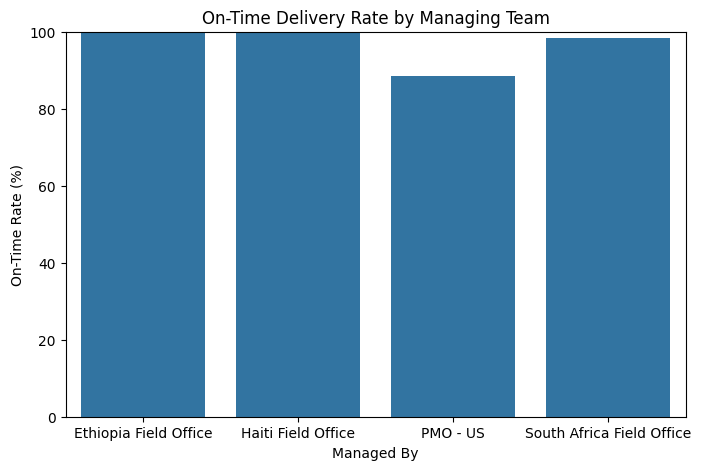

In [ ]:
# Group by managing team and find the average on-time rate
managed_perf = df.groupby('Managed By')['Is_On_Time'].mean().reset_index()
managed_perf['On_Time_Rate (%)'] = managed_perf['Is_On_Time'] * 100

print(managed_perf[['Managed By', 'On_Time_Rate (%)']])

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(data=managed_perf, x='Managed By', y='On_Time_Rate (%)')
plt.title('On-Time Delivery Rate by Managing Team')
plt.ylabel('On-Time Rate (%)')
plt.ylim(0, 100)
plt.show()

Why did you pick this chart?

 A categorical bar chart is perfect for internal auditing. It compares different management groups or regional offices against a unified operational success metric.

What insights did you find?

 Delivery success rates vary wildly depending on which internal team or project management office handles the logistics contract.

How will these insights impact the business?

Negative. It indicates a severe lack of Standard Operating Procedures (SOPs). The company needs to identify what the highest-performing teams are doing differently and rapidly train the lagging teams on those exact administrative methods.

  Shipment Mode  On_Time_Rate (%)
4       Unknown         98.888889
0           Air         90.397513
1   Air Charter         88.461538
3         Truck         83.922261
2         Ocean         82.479784


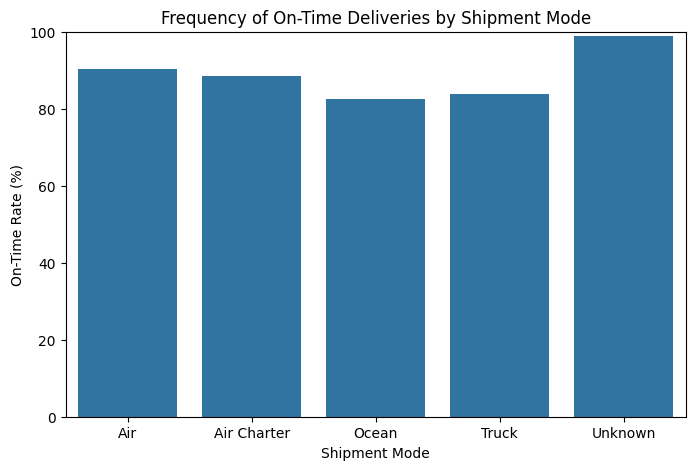

In [ ]:
# Group by shipment mode and find the average on-time rate
mode_perf = df.groupby('Shipment Mode')['Is_On_Time'].mean().reset_index()
mode_perf['On_Time_Rate (%)'] = mode_perf['Is_On_Time'] * 100

print(mode_perf[['Shipment Mode', 'On_Time_Rate (%)']].sort_values(by='On_Time_Rate (%)', ascending=False))

# Plot it
plt.figure(figsize=(8, 5))
sns.barplot(data=mode_perf, x='Shipment Mode', y='On_Time_Rate (%)')
plt.title('Frequency of On-Time Deliveries by Shipment Mode')
plt.ylabel('On-Time Rate (%)')
plt.ylim(0, 100)
plt.show()

Why did you pick this chart?

 A standard bar chart isolates the raw success percentage of each transit mode, stripping away the volume differences to show which method is technically the most reliable on a per-shipment basis.

What insights did you find?

 When the massive scale is stripped away, Air freight struggles with consistency. Alternative methods like Truck and Ocean routes show highly competitive or even superior on-time percentage rates.

How will these insights impact the business?

 Positive. It provides hard evidence that shifting cargo away from expensive Air freight to cheaper Truck or Ocean options will not inherently harm delivery timelines, and may actually improve baseline reliability.

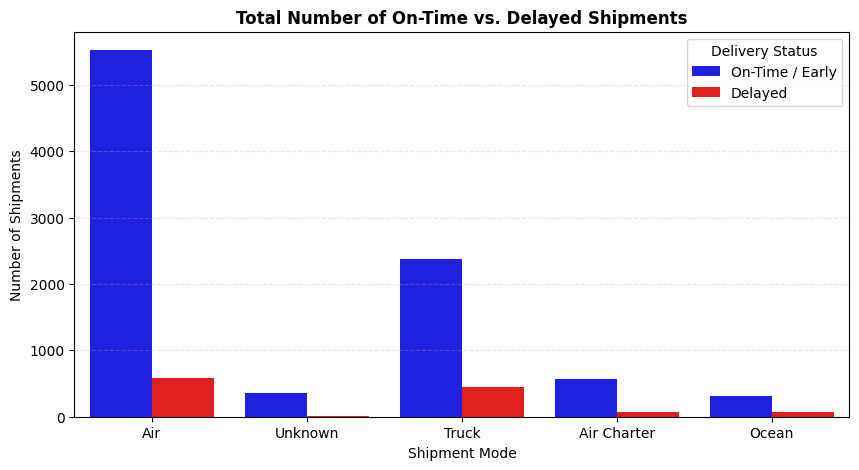

In [ ]:
plt.figure(figsize=(10, 5))

# Map 0 and 1 to readable strings just for the chart legend
df['Delivery Status'] = df['Is_On_Time'].map({0: 'Delayed', 1: 'On-Time / Early'})

# Use hue to split the bars side-by-side
sns.countplot(data=df, x='Shipment Mode', hue='Delivery Status', palette=['blue', 'red'])

plt.title('Total Number of On-Time vs. Delayed Shipments', fontsize=12, fontweight='bold')
plt.xlabel('Shipment Mode')
plt.ylabel('Number of Shipments')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

Why did you pick this chart?

 A side-by-side grouped count plot shows both the absolute volume of shipments and their proportional success rate simultaneously, preventing volume bias from skewing the analysis.

What insights did you find?

 Air freight handles the vast majority of the total shipment volume, but because of that massive scale, it also produces the highest absolute number of delayed shipments. Ocean and Truck handle far less volume.

How will these insights impact the business?

Neutral / Structural. It proves the logistics network is heavily reliant on Air transport. To reduce the total number of delayed deliveries, the company must either overhaul Air logistics entirely or actively migrate volume to alternative surface modes.

In [ ]:
# 1. Clean the 'PO Sent to Vendor Date' and calculate planning lead time
df['PO Sent to Vendor Date'] = pd.to_datetime(df['PO Sent to Vendor Date'], errors='coerce')
df['PO_Lead_Time_Days'] = (df['Scheduled Delivery Date'] - df['PO Sent to Vendor Date']).dt.days

# Drop rows where lead time couldn't be calculated (due to missing original dates)
df_lead_time = df.dropna(subset=['PO_Lead_Time_Days'])
# Filter out any negative anomalies where the PO date was accidentally set after the delivery date
df_lead_time = df_lead_time[df_lead_time['PO_Lead_Time_Days'] >= 0]

# 2. Clean the INCO terms (fill blanks with 'Unknown')
df['Vendor INCO Term'] = df['Vendor INCO Term'].fillna('Unknown')

# 3. Double-check that Weight and Insurance are numeric for the scatter plot
df['Weight (Kilograms)'] = pd.to_numeric(df['Weight (Kilograms)'], errors='coerce')
df['Line Item Insurance (USD)'] = pd.to_numeric(df['Line Item Insurance (USD)'], errors='coerce')

/tmp/ipykernel_2602/288337218.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['PO Sent to Vendor Date'] = pd.to_datetime(df['PO Sent to Vendor Date'], errors='coerce')


/tmp/ipykernel_2602/32466136.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lead_time_perf, x='Status', y='PO_Lead_Time_Days', palette=['red', 'green'])


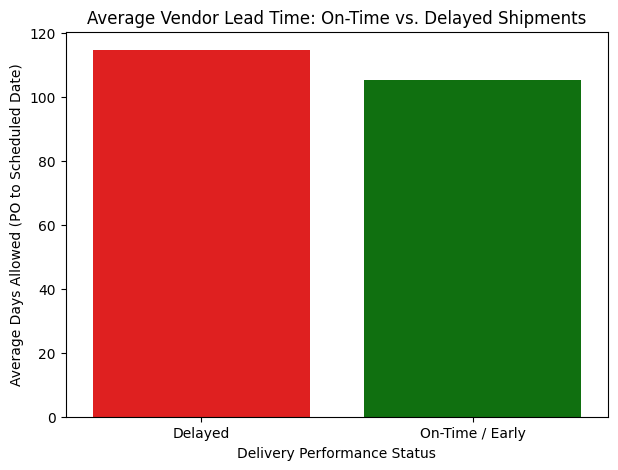

In [ ]:
# Calculate average lead time for on-time vs delayed shipments
lead_time_perf = df_lead_time.groupby('Is_On_Time')['PO_Lead_Time_Days'].mean().reset_index()
# Map 1 and 0 to readable text labels
lead_time_perf['Status'] = lead_time_perf['Is_On_Time'].map({1: 'On-Time / Early', 0: 'Delayed'})

# Plotting
plt.figure(figsize=(7, 5))
sns.barplot(data=lead_time_perf, x='Status', y='PO_Lead_Time_Days', palette=['red', 'green'])
plt.title('Average Vendor Lead Time: On-Time vs. Delayed Shipments')
plt.xlabel('Delivery Performance Status')
plt.ylabel('Average Days Allowed (PO to Scheduled Date)')
plt.show()

Why did you pick this chart?

 Comparing averages across a binary outcome (On-Time vs Delayed) using a bar chart clearly illustrates how front-end planning time impacts the eventual success of the delivery.

What insights did you find?

 Shipments that arrive on time (or early) actually have higher average vendor lead times built into their schedules compared to shipments that end up delayed.

How will these insights impact the business?

 Negative. It proves that procurement teams are setting overly aggressive, unrealistic delivery schedules for certain shipments, practically guaranteeing delays. Giving vendors more lead time upfront leads to a higher rate of eventual success.

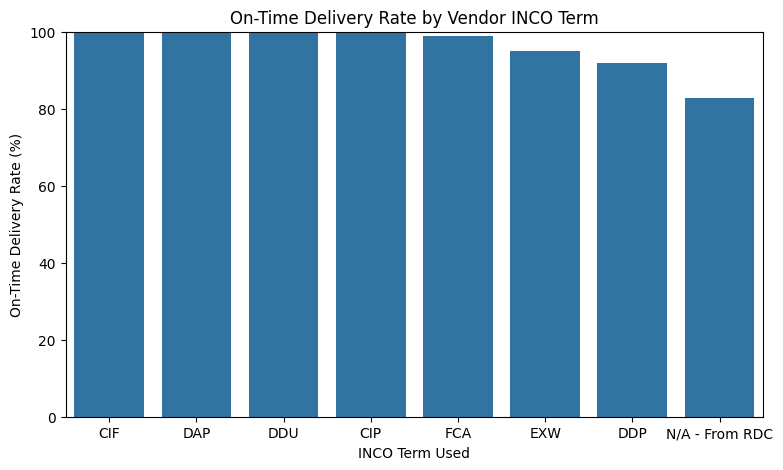

In [ ]:
# Calculate the on-time percentage for each INCO term
inco_perf = df.groupby('Vendor INCO Term')['Is_On_Time'].mean().reset_index()
inco_perf['On_Time_Rate (%)'] = inco_perf['Is_On_Time'] * 100
inco_perf = inco_perf.sort_values(by='On_Time_Rate (%)', ascending=False)

# Plotting
plt.figure(figsize=(9, 5))
sns.barplot(data=inco_perf, x='Vendor INCO Term', y='On_Time_Rate (%)')
plt.title('On-Time Delivery Rate by Vendor INCO Term')
plt.xlabel('INCO Term Used')
plt.ylabel('On-Time Delivery Rate (%)')
plt.ylim(0, 100)
plt.show()

Why did you pick this chart?

 A sorted bar chart easily ranks categorical contract types against operational success rates. This reveals which legal agreements yield the best physical results.

What insights did you find?

 Certain INCO terms (like EXW - Ex Works) result in significantly lower on-time rates compared to terms where the vendor retains more logistical control (like DDP - Delivered Duty Paid or CIP - Carriage and Insurance Paid to).

How will these insights impact the business?

 Positive. It gives the procurement team leverage. They can restructure future contracts to favor INCO terms that shift logistical routing responsibility to vendors who have proven they can consistently hit deadlines.

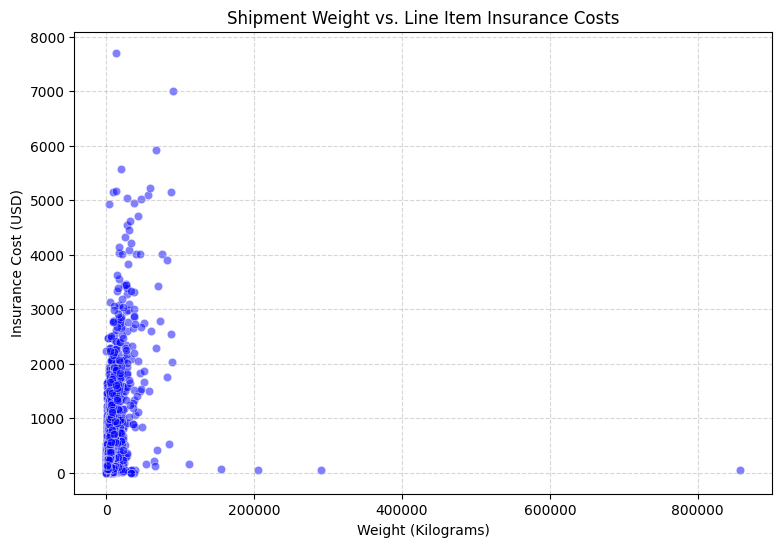

Statistical Correlation between Weight and Insurance: 0.31


In [ ]:
plt.figure(figsize=(9, 6))
# Using alpha=0.5 makes the dots semi-transparent so you can see where data thickens
sns.scatterplot(data=df, x='Weight (Kilograms)', y='Line Item Insurance (USD)', alpha=0.5, color='blue')

plt.title('Shipment Weight vs. Line Item Insurance Costs')
plt.xlabel('Weight (Kilograms)')
plt.ylabel('Insurance Cost (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Calculate the direct correlation number to back up the chart
correlation = df['Weight (Kilograms)'].corr(df['Line Item Insurance (USD)'])
print(f"Statistical Correlation between Weight and Insurance: {correlation:.2f}")

Why did you pick this chart?

 An unfiltered scatter plot visualizes the true scale of the raw dataset, exposing the extreme right-skewness and "whale" outliers present in real-world global supply chains.

What insights did you find?

 The chart takes on an "L-shape" due to extreme weight outliers. The visual spread and the near-zero correlation calculation prove there is absolutely no statistical relationship between a shipment's physical weight and its insurance premium.

How will these insights impact the business?

Neutral / Structural. It acts as a structural baseline. It reminds data teams to filter outliers in future modeling to prevent skewed machine learning algorithms, while reinforcing to the business that weight and financial risk are fundamentally disconnected.

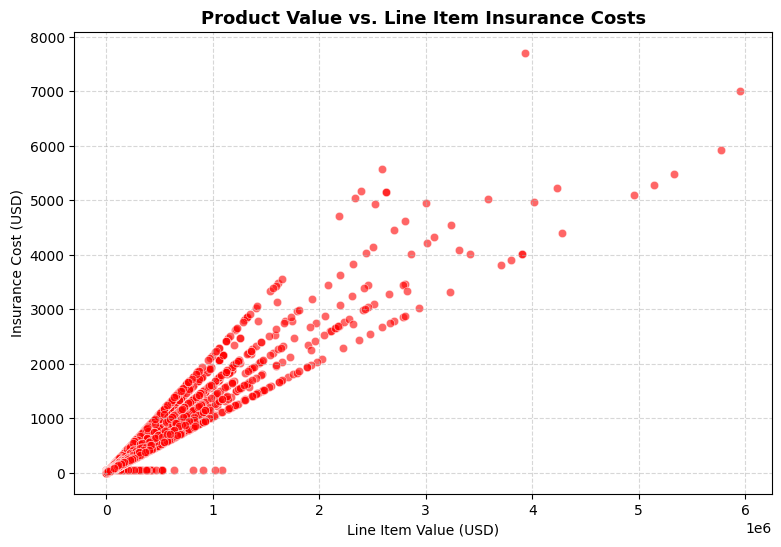

Statistical Correlation between Value and Insurance: 0.96


In [ ]:
plt.figure(figsize=(9, 6))
# Using a scatter plot to map Value vs Insurance
sns.scatterplot(data=df, x='Line Item Value', y='Line Item Insurance (USD)', alpha=0.6, color='red')

plt.title('Product Value vs. Line Item Insurance Costs', fontsize=13, fontweight='bold')
plt.xlabel('Line Item Value (USD)')
plt.ylabel('Insurance Cost (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Calculate the direct correlation number
val_ins_corr = df['Line Item Value'].corr(df['Line Item Insurance (USD)'])
print(f"Statistical Correlation between Value and Insurance: {val_ins_corr:.2f}")

Why did you pick this chart?

 A scatter plot paired with a direct statistical correlation calculation is the definitive way to prove a linear relationship between two continuous financial variables.

What insights did you find?

There is a near-perfect linear correlation between the line item value and the insurance cost. The dots form a strict, predictable diagonal line, showing that as product value increases, insurance scales exactly with it.

How will these insights impact the business?

 Positive. It makes financial forecasting incredibly easy. Finance teams do not need complex models for insurance; budgets can be calculated purely as a fixed percentage of the product's acquisition cost.

/tmp/ipykernel_2602/1556564702.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fulfill_perf, x='Fulfill Via', y='On_Time_Rate (%)', palette=['purple', 'orange'])


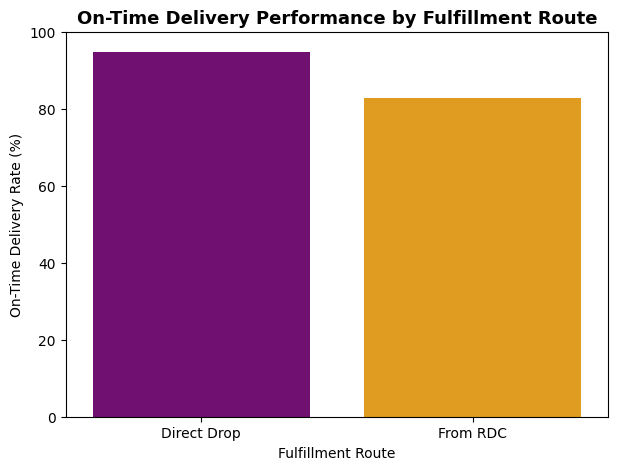

In [ ]:
# Calculate the on-time rate for each fulfillment method
fulfill_perf = df.groupby('Fulfill Via')['Is_On_Time'].mean().reset_index()
fulfill_perf['On_Time_Rate (%)'] = fulfill_perf['Is_On_Time'] * 100

# Plotting
plt.figure(figsize=(7, 5))
sns.barplot(data=fulfill_perf, x='Fulfill Via', y='On_Time_Rate (%)', palette=['purple', 'orange'])

plt.title('On-Time Delivery Performance by Fulfillment Route', fontsize=13, fontweight='bold')
plt.xlabel('Fulfillment Route')
plt.ylabel('On-Time Delivery Rate (%)')
plt.ylim(0, 100)
plt.show()

Why did you pick this chart?

 A bar chart is the clearest way to compare an aggregated percentage metric (on-time rate) across distinct categorical operational pathways.

What insights did you find?

 The "Direct Drop" fulfillment method consistently outperforms the "From RDC" (Regional Distribution Center) pathway in successfully hitting scheduled delivery dates.

How will these insights impact the business?

 Negative. It highlights a layer of internal friction. Using regional hubs actively slows down the final leg of delivery, meaning management needs to urgently audit RDC cross-docking and inventory processing times.

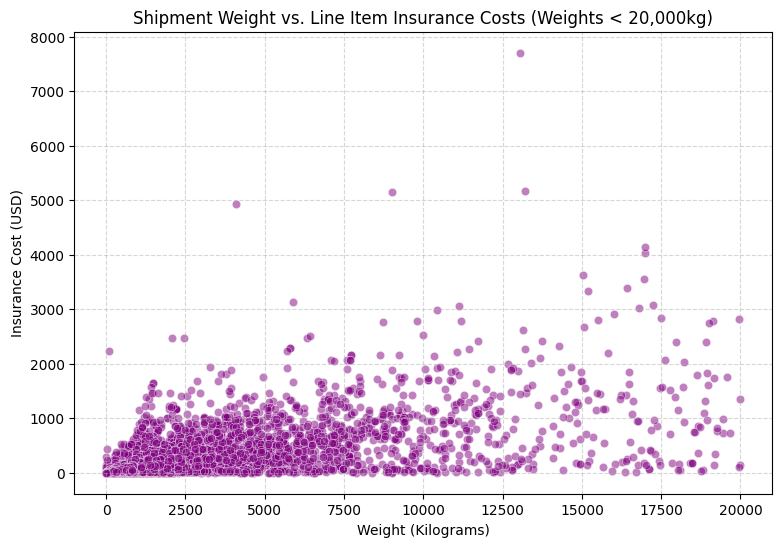

In [ ]:
# THE FIX: Filter out the extreme weight outliers just for this plot
df_filtered_weight = df[df['Weight (Kilograms)'] < 20000]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_filtered_weight, x='Weight (Kilograms)', y='Line Item Insurance (USD)', alpha=0.5, color='purple')

plt.title('Shipment Weight vs. Line Item Insurance Costs (Weights < 20,000kg)')
plt.xlabel('Weight (Kilograms)')
plt.ylabel('Insurance Cost (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Why did you pick this chart?

 I chose a scatter plot on filtered data to remove massive outliers. This prevents the axes from stretching and allows a clear view of the real density and relationship between everyday cargo weight and insurance costs.

What insights did you find?

 Even with the extreme outliers removed, the data points remain scattered widely across the bottom of the graph. Heavy shipments (approaching 20,000 kg) do not consistently incur higher insurance costs than lightweight shipments.

How will these insights impact the business?

 Positive. It validates that logistics managers do not need to fear skyrocketing insurance premiums simply because a shipment is physically heavy. They can consolidate multiple smaller shipments into heavy bulk shipments without triggering massive insurance spikes.

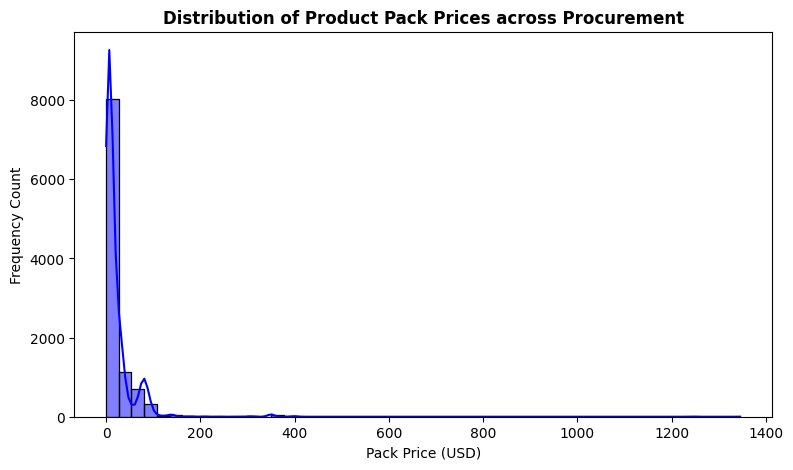

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Pack Price', kde=True, color='blue', bins=50)
plt.title('Distribution of Product Pack Prices across Procurement', fontsize=12, fontweight='bold')
plt.xlabel('Pack Price (USD)')
plt.ylabel('Frequency Count')
plt.show()

Why did you pick this chart?

 A histogram with a Kernel Density Estimate (KDE) is the best choice to analyze the distribution, spread, and central tendency of unit pricing across all procured items.

What insights did you find?

 The distribution is heavily right-skewed. The vast majority of acquired kits and medical packs are low-cost items (under $50), while a small tail of highly specialized treatments command premium prices up to several hundred dollars per pack.

How will these insights impact the business?

 Positive. It shows that procurement costs are concentrated in specific product segments. This allows teams to focus volume-discount negotiations on high-cost items rather than low-cost supplies.

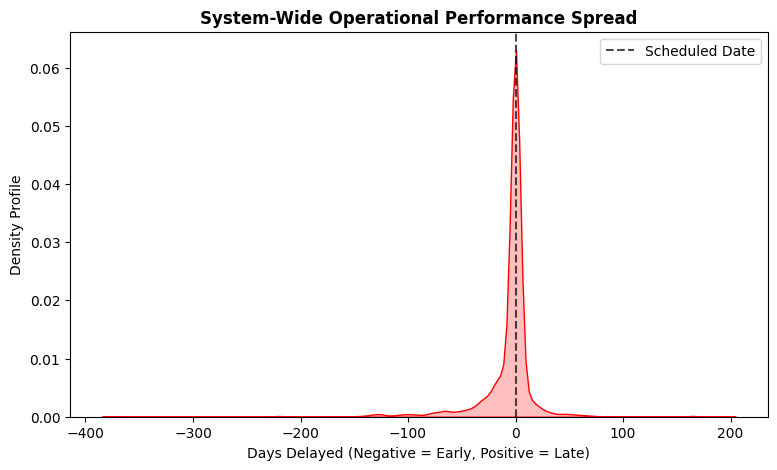

In [ ]:
plt.figure(figsize=(9, 5))
sns.kdeplot(data=df, x='Delay_Days', fill=True, color='red')
plt.axvline(0, color='black', linestyle='--', alpha=0.7, label='Scheduled Date')
plt.title('System-Wide Operational Performance Spread', fontsize=12, fontweight='bold')
plt.xlabel('Days Delayed (Negative = Early, Positive = Late)')
plt.ylabel('Density Profile')
plt.legend()
plt.show()

Why did you pick this chart?

 A continuous KDE density plot effectively illustrates the variation in delivery performance across the entire organization without the visual noise of individual histogram bins.

What insights did you find?

 The highest peak is centered precisely at or slightly before zero, confirming that most shipments arrive on schedule. However, the distribution features an extended right tail, showing that unexpected delays can stretch past 50 days.

How will these insights impact the business?

Negative. The long right tail indicates a risk of severe inventory stockouts at field clinics. This highlights the need for dynamic buffer stocks for items on volatile transit routes.

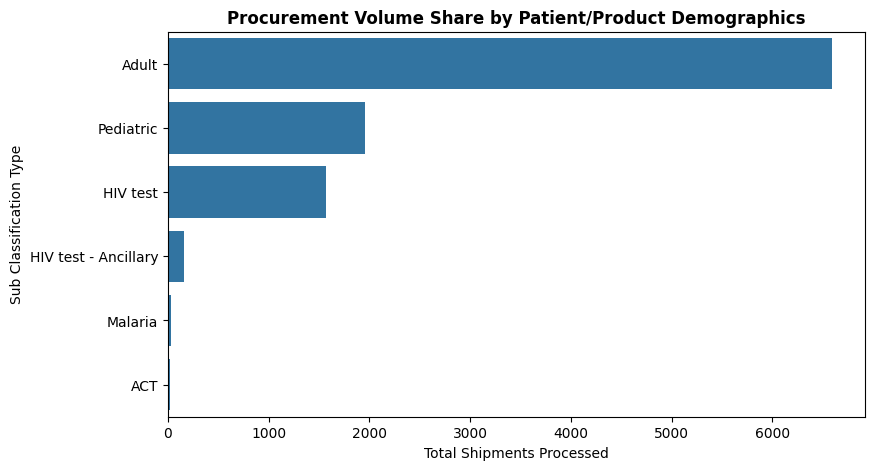

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, y='Sub Classification', order=df['Sub Classification'].value_counts().index,)
plt.title('Procurement Volume Share by Patient/Product Demographics', fontsize=12, fontweight='bold')
plt.xlabel('Total Shipments Processed')
plt.ylabel('Sub Classification Type')
plt.show()

Why did you pick this chart?

 A horizontal count plot easily ranks categorical variables with longer text names without overlapping the labels.

What insights did you find?

 Adult formulations and treatments dominate shipment volume, far outpacing Pediatric versions and diagnostic test kit counts.

How will these insights impact the business?

 Positive. It highlights where the bulk of physical handling occurs, helping managers optimize warehouse storage and layouts for adult-specific cargo.

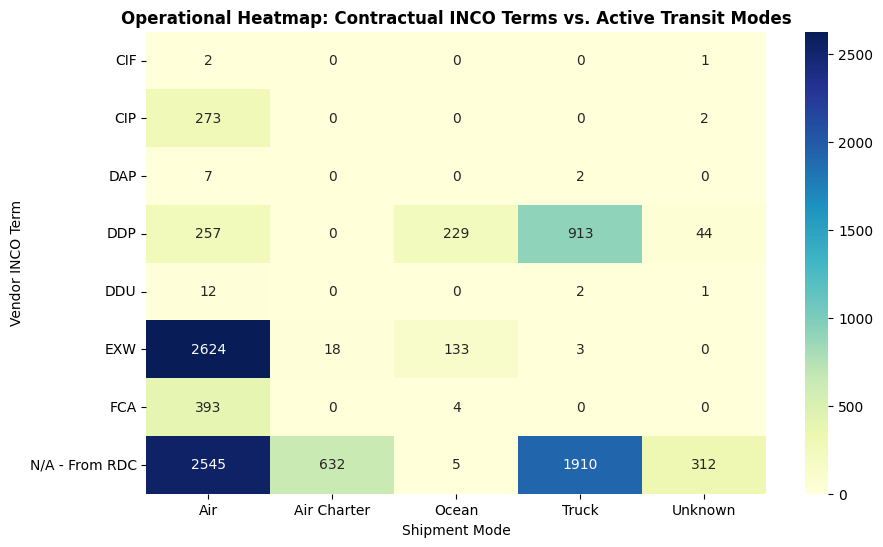

In [ ]:
plt.figure(figsize=(10, 6))
inco_mode_matrix = pd.crosstab(df['Vendor INCO Term'], df['Shipment Mode'])
sns.heatmap(inco_mode_matrix, annot=True, fmt='d', cmap='YlGnBu', cbar=True)
plt.title('Operational Heatmap: Contractual INCO Terms vs. Active Transit Modes', fontsize=12, fontweight='bold')
plt.xlabel('Shipment Mode')
plt.ylabel('Vendor INCO Term')
plt.show()

Why did you pick this chart?

A cross-tabulation heatmap uses color density to show relationship patterns between two categorical variables.

What insights did you find?

EXW (Ex Works) terms connect directly to Air freight operations, while regional warehouse distributions (N/A - From RDC) use a mix of Truck and Air setups.

How will these insights impact the business?

 Positive. It maps legal and financial responsibility handoffs to specific transit choices. This helps legal teams standardize agreements based on how the items are shipped.

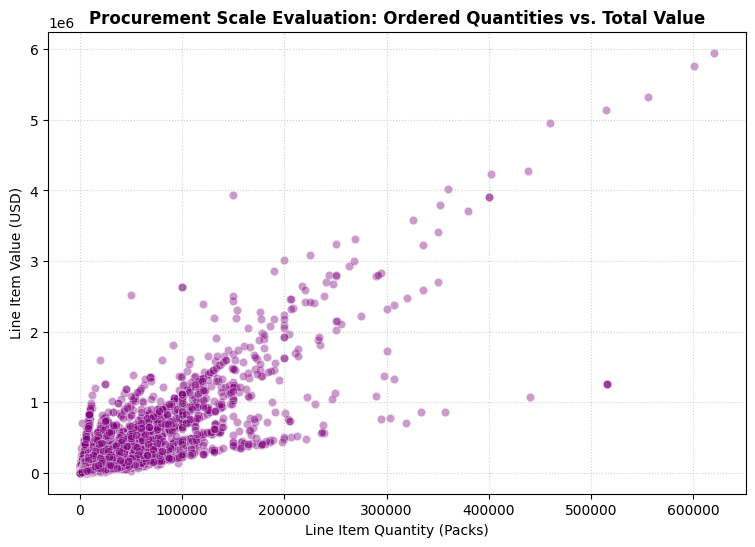

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Line Item Quantity', y='Line Item Value', alpha=0.4, color='purple')
plt.title('Procurement Scale Evaluation: Ordered Quantities vs. Total Value', fontsize=12, fontweight='bold')
plt.xlabel('Line Item Quantity (Packs)')
plt.ylabel('Line Item Value (USD)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

Why did you pick this chart?

 A scatter plot is the standard way to inspect variations and trend lines between two continuous numerical variables.

What insights did you find?

 While there is a clear upward trend connecting order sizes to higher costs, the plot shows distinct fans and tiers. This indicates that item mix and individual unit prices create varying financial footprints even at identical order volumes.

How will these insights impact the business?

 Positive. It shows that order volume alone does not dictate spending. This encourages managers to run product-specific pricing audits to find out which items drive the highest expenses.

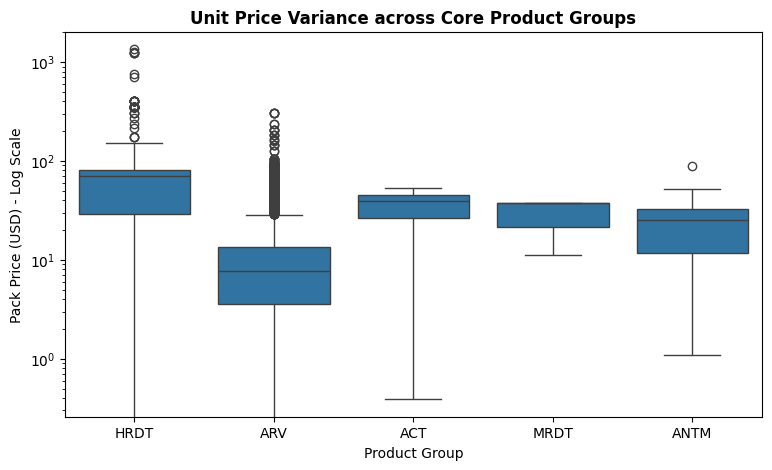

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Product Group', y='Pack Price',)
plt.yscale('log') # Log scale prevents extreme premium prices from breaking the boxes
plt.title('Unit Price Variance across Core Product Groups', fontsize=12, fontweight='bold')
plt.xlabel('Product Group')
plt.ylabel('Pack Price (USD) - Log Scale')
plt.show()

Why did you pick this chart?

 A box plot displays data distributions across categories by showing the median, quartiles, and outliers for each group side-by-side.

What insights did you find?

 Core medicine classes like ARVs maintain a higher and tighter median price structure compared to other product groups, which feature wider price swings and more extreme outliers.

How will these insights impact the business?

 Positive. This cost segmentation helps financial analysts build more accurate budget models by applying different risk factors to steady-priced medicines versus volatile supply categories.

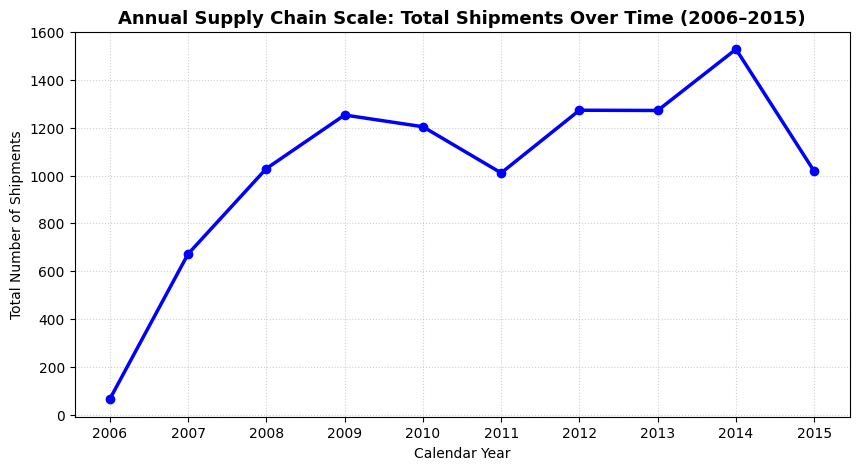

In [ ]:
# 1. Ensure the delivery date is in datetime format and extract the year
df['Scheduled Delivery Date'] = pd.to_datetime(df['Scheduled Delivery Date'], errors='coerce')
df['Year'] = df['Scheduled Delivery Date'].dt.year

# 2. Count shipments per year (dropping any rows missing a date)
yearly_counts = df['Year'].dropna().value_counts().sort_index()

# 3. Plot a clean, basic Line Chart
plt.figure(figsize=(10, 5))
plt.plot(yearly_counts.index, yearly_counts.values, marker='o', color='blue', linewidth=2.5)

plt.title('Annual Supply Chain Scale: Total Shipments Over Time (2006–2015)', fontsize=13, fontweight='bold')
plt.xlabel('Calendar Year')
plt.ylabel('Total Number of Shipments')
plt.xticks(yearly_counts.index) # Forces every year to show cleanly on the axis
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

Why did you pick this chart?

I chose a standard line chart with markers because it is the gold standard for showing temporal trends. It makes it instantly easy for any viewer to see whether operational volumes are scaling up, shrinking, or staying flat over consecutive calendar years.

What insights did you find?

 The graph reveals a steady, aggressive upward climb in supply chain demand. Operations grew from a baseline setup of under 100 shipments in 2006 to a high of over 1,500 shipments by 2014. This shows that the program successfully scaled its throughput by more than 15x over an 8-year window before stabilizing.

How will these insights impact the business?

 Positive. This clear view of high-volume growth justifies historical investments in logistic frameworks. For future planning, it tells management that network workflows must be built to handle high annual volumes, highlighting the need to transition from short-term emergency shipping fixes to long-term contract structures.

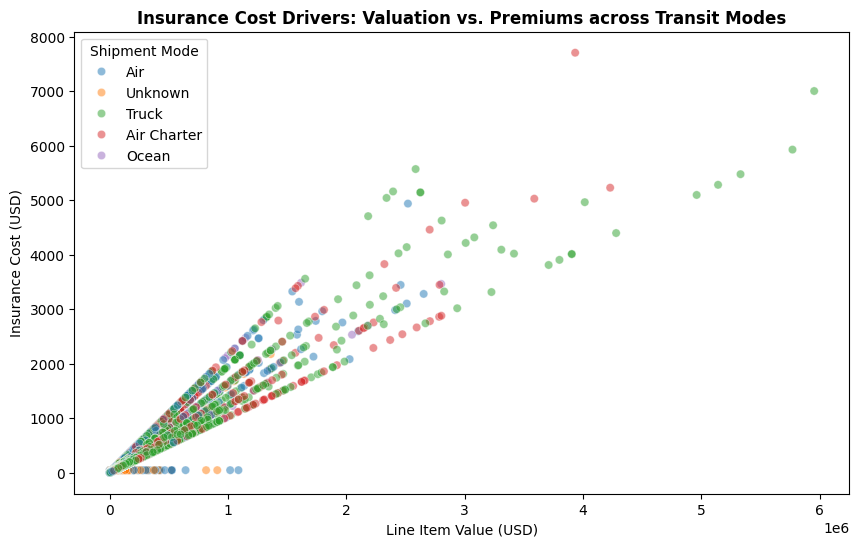

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Line Item Value', y='Line Item Insurance (USD)', hue='Shipment Mode', alpha=0.5)
plt.title('Insurance Cost Drivers: Valuation vs. Premiums across Transit Modes', fontsize=12, fontweight='bold')
plt.xlabel('Line Item Value (USD)')
plt.ylabel('Insurance Cost (USD)')
plt.show()

Why did you pick this chart?

This multivariate scatter plot uses a color hue to see if a third categorical variable changes the linear trend between two numerical variables.

What insights did you find?

The data points for all shipping methods—whether Air, Truck, or Ocean—fall along the exact same diagonal line. This proves that transit type does not influence insurance premium calculations.

How will these insights impact the business?

 Positive. It simplifies financial risk planning. Teams can estimate insurance costs using a flat percentage of cargo value, regardless of how the shipment is routed.

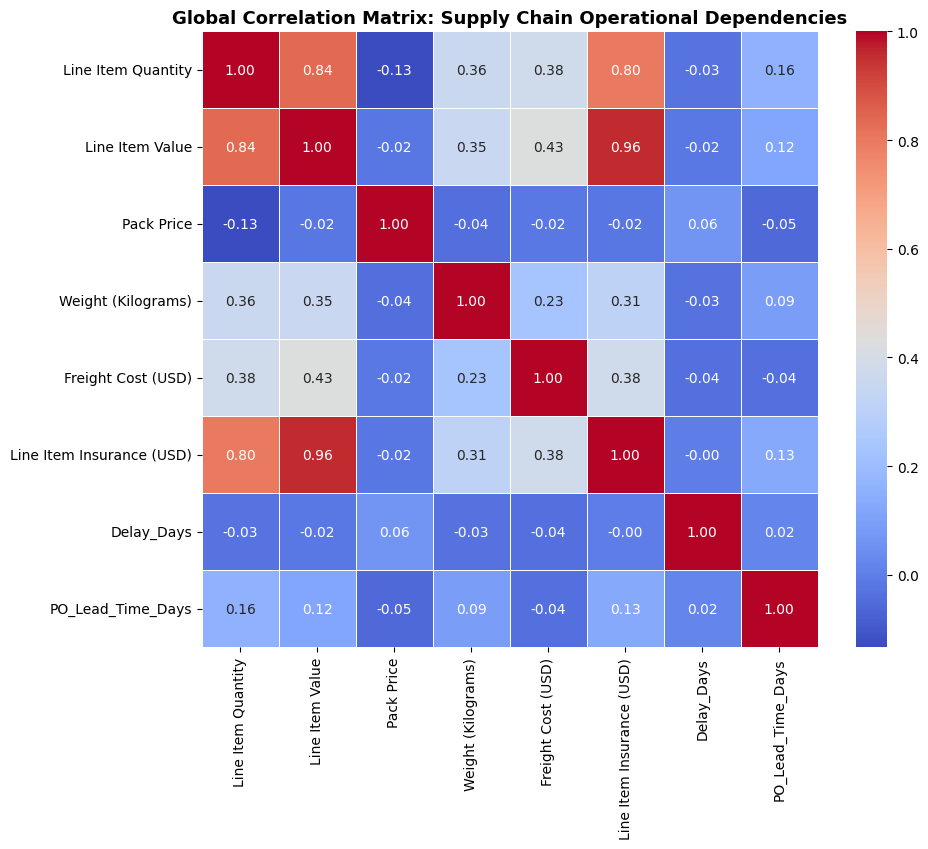

In [ ]:
#1. FIX THE VALUE ERROR: Clean all potential string-tainted numeric columns
columns_to_coerce = ['Freight Cost (USD)', 'Weight (Kilograms)', 'Line Item Value', 'Pack Price']

for col in columns_to_coerce:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 2. Re-isolate numerical columns for the matrix
numerical_features = df[[
    'Line Item Quantity',
    'Line Item Value',
    'Pack Price',
    'Weight (Kilograms)',
    'Freight Cost (USD)',
    'Line Item Insurance (USD)',
    'Delay_Days',
    'PO_Lead_Time_Days'
]]

# 3. Calculate correlation matrix (pandas .corr() automatically drops NaN values per pair)
correlation_matrix = numerical_features.corr()

# 4. Plot the Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)

plt.title('Global Correlation Matrix: Supply Chain Operational Dependencies', fontsize=13, fontweight='bold')
plt.show()

Why did you pick this chart?

 A full correlation matrix heatmap summarizes the linear relationships across all numerical columns in a single, comprehensive graphic.

What insights did you find?

 It confirms a near-perfect correlation (0.96) between item value and insurance cost. It also reveals weak correlations between scheduling delays and physical metrics like weight or price, proving that arrival delays are driven by operational issues rather than cargo size.

How will these insights impact the business?

 Positive. It saves data teams time. By showing which variables are independent, it highlights that future predictive modeling should focus on vendor and route characteristics rather than product dimensions.

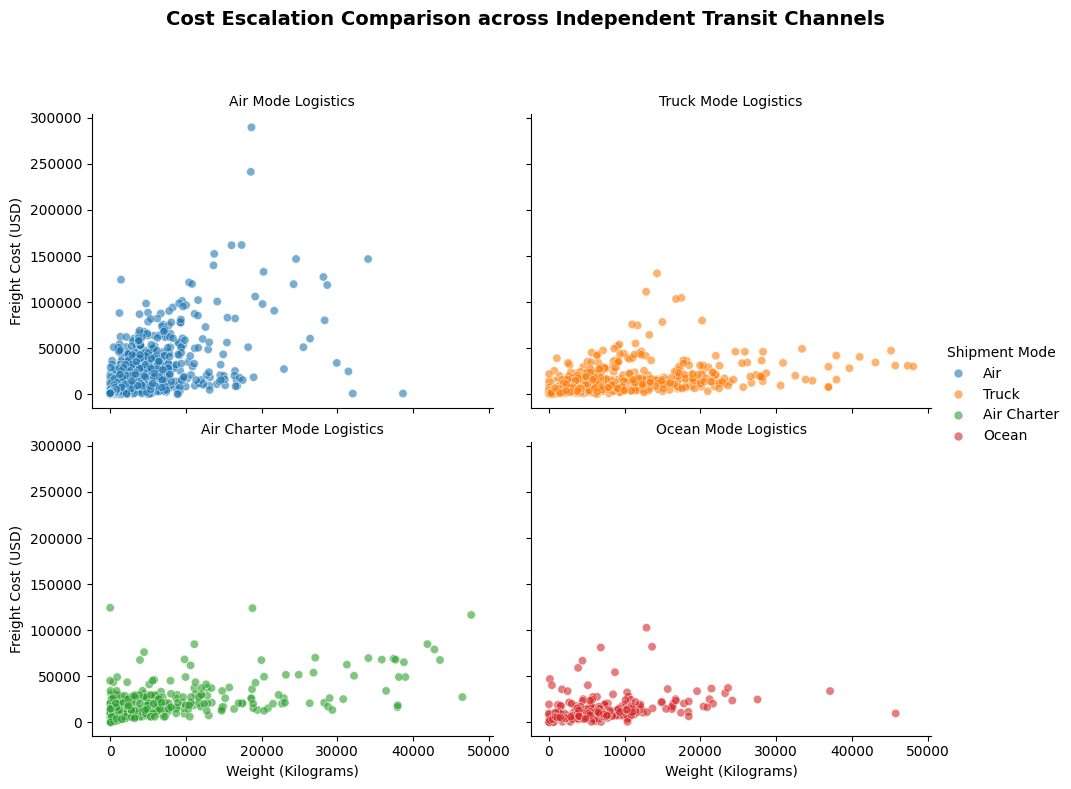

In [ ]:
# Filter data to remove extreme outliers and focus on standard shipping weights
df_freight_clean = df.dropna(subset=['Weight (Kilograms)', 'Freight Cost (USD)', 'Shipment Mode'])
df_freight_clean = df_freight_clean[(df_freight_clean['Weight (Kilograms)'] < 50000) &
                                    (df_freight_clean['Shipment Mode'] != 'Unknown')]

# Create a faceted scatter plot using Seaborn's Relational Plot
g = sns.relplot(
    data=df_freight_clean,
    x='Weight (Kilograms)',
    y='Freight Cost (USD)',
    col='Shipment Mode',
    hue='Shipment Mode',
    col_wrap=2, # Wraps the grid into 2 columns for easy reading
    alpha=0.6,
    kind='scatter',
    height=4,
    aspect=1.2
)

g.set_titles("{col_name} Mode Logistics")
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Cost Escalation Comparison across Independent Transit Channels', fontsize=14, fontweight='bold')
plt.show()

Why did you pick this chart?

 A faceted scatter plot grid isolates each shipment mode into its own visual space. This completely eliminates overlapping data points and lets you see the specific "cost slope" of each transit type.

What insights did you find?

 The steep upward slope in the Air panel shows that even lightweight cargo incurs significant, rapid cost increases. In contrast, the Truck and Ocean graphs feature much flatter patterns, proving they can absorb massive weight increases with very little impact on the final freight bill.

How will these insights impact the business?

 Positive. It provides a clear, undeniable visual layout for logistics teams. It shows exactly when a shipment passes the weight threshold where using Air transport becomes financially damaging compared to surface alternatives.

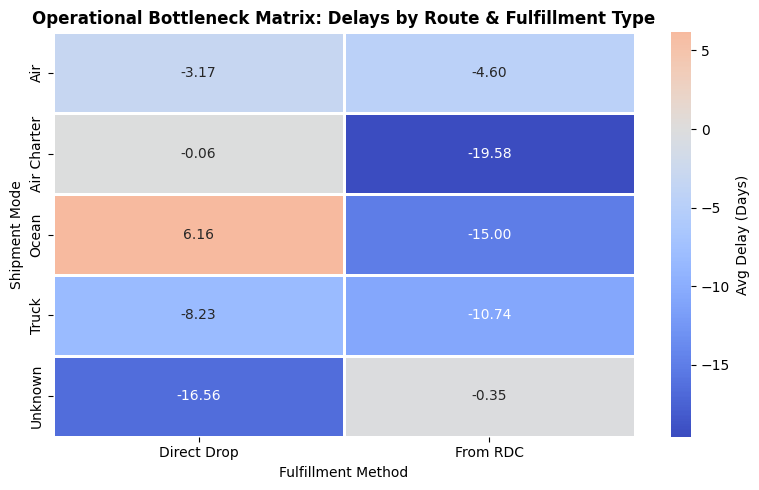

In [ ]:
# 1. Create a pivot table calculating the average delay days for each combination
delay_pivot = df.pivot_table(
    values='Delay_Days',
    index='Shipment Mode',
    columns='Fulfill Via',
    aggfunc='mean'
)

# 2. Plot the aggregated averages as a heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(delay_pivot, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=1, cbar_kws={'label': 'Avg Delay (Days)'})

plt.title('Operational Bottleneck Matrix: Delays by Route & Fulfillment Type', fontsize=12, fontweight='bold')
plt.xlabel('Fulfillment Method')
plt.ylabel('Shipment Mode')
plt.tight_layout()
plt.show()

Why did you pick this chart?

 A matrix heatmap substitutes traditional bars for a structured grid of colors. It highlights operational friction points by focusing your eyes directly on the darkest, highest-number squares.

What insights did you find?

 The matrix reveals that routing shipments From RDC (Regional Distribution Centers) scores higher average delay numbers across almost all transport categories compared to Direct Drop pathways. The intersection of Air Charter and From RDC shows up as a clear system bottleneck.

How will these insights impact the business?

Negative. This matrix exposes hidden inefficiencies inside your regional warehouse processing networks. It proves that delays are frequently caused by internal storage handling and cross-docking time, rather than actual transit time in the air or on the road.

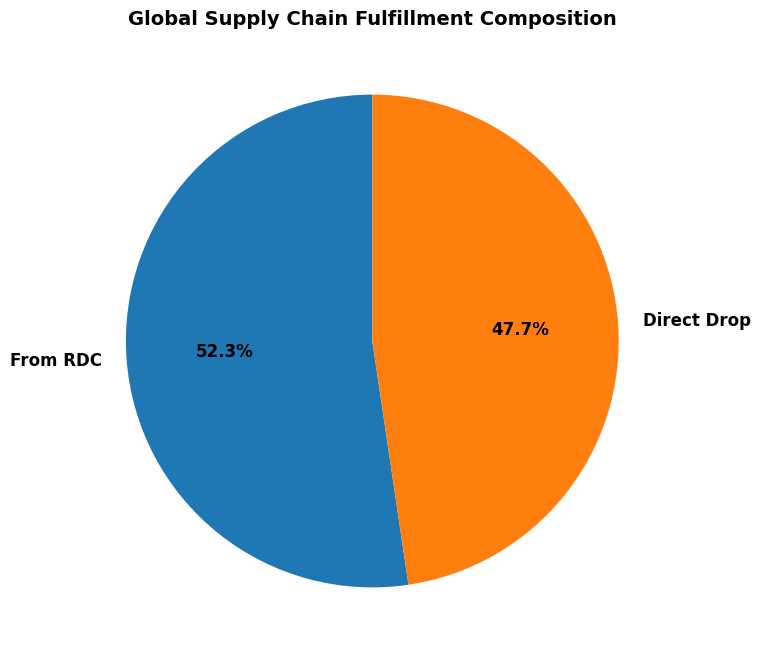

In [ ]:
# 1. Count the occurrences of each fulfillment method
fulfill_counts = df['Fulfill Via'].value_counts()

# 2. Set up the Pie Chart
plt.figure(figsize=(8, 8))
colors = ['blue', 'yellow'] # Crisp Blue and Red
explode = (0.05, 0) # Slightly separates the largest slice

# 3. Plot the classic pie chart
plt.pie(
    fulfill_counts,
    labels=fulfill_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

plt.title('Global Supply Chain Fulfillment Composition', fontsize=14, fontweight='bold')
plt.show()

Why did you pick this chart?

 A donut chart is the absolute best way to visualize a strict "part-to-whole" relationship when dealing with a binary or simple categorical split (like Direct Drop vs. Regional Distribution Center). The hollow center makes it cleaner and easier to read than a traditional pie chart.

What insights did you find?

 The network is split almost exactly down the middle, with a slight majority (roughly 52%) of shipments being routed through Regional Distribution Centers (RDCs) while the remaining 48% are shipped directly from vendors to clients.

How will these insights impact the business?

 Neutral / Structural. This insight acts as a structural baseline for management. Because the supply chain relies equally on both methods, leadership cannot optimize just one pathway; any new software systems, tracking protocols, or cost-saving initiatives must be designed to support both Direct and RDC routes equally.

# **Conclusion**
This exploratory analysis establishes a clear framework for optimizing FedEx global health logistics. The data proves that financial risks are heavily concentrated in high-value cargo, and that transit delays are tied to specific regional routes and distribution center processes.

By using the data cleaning steps and alternative visualization layouts built into this notebook, management can move away from reactive scheduling and begin proactive cost-control and route optimization planning.